
# CM2604 – Machine Learning Coursework

## Customer Churn Prediction Using Machine Learning

**Student Name:** Janithma Peiris

**Module:** CM2604 – Machine Learning

**Dataset:** Telco Customer Churn Dataset

### Project Overview

This project aims to develop and evaluate machine learning models to predict whether a telecommunications customer is likely to leave the company. The project uses exploratory data analysis, data preprocessing, model training, hyperparameter tuning, and evaluation to compare the performance of three classification algorithms:

- K-Nearest Neighbours (KNN)
- Logistic Regression
- Random Forest

The project also considers the ethical implications of using machine learning for customer churn prediction, identifies the limitations of the developed models, and discusses possible future improvements.



## 1. Introduction

Customer churn occurs when a customer stops using a company's products or services. Predicting customer churn is important for telecommunications companies because losing customers can affect revenue and business growth.

Machine learning can help identify customers who are more likely to leave by analysing information such as customer tenure, monthly charges, contract type, and the services they use.

In this project, three machine learning algorithms—K-Nearest Neighbours (KNN), Logistic Regression, and Random Forest—will be developed and compared using the Telco Customer Churn dataset. Their performance will be evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

The main objective is to identify a suitable classification model for predicting customer churn while considering the limitations and ethical responsibilities associated with using customer data.



## 2. Dataset Description

The dataset used in this project is the **Telco Customer Churn dataset**. It contains information about telecommunications customers, their subscribed services, account details, and whether they left the company.

The dataset includes the following types of information:

- **Customer information:** Customer ID and gender.
- **Service information:** Internet service, phone service, and additional services.
- **Account information:** Contract type, payment method, monthly charges, and total charges.
- **Target variable:** Churn, which indicates whether a customer left the company.

The target variable is `Churn`. It contains two classes: `Yes` and `No`. This makes the task a **binary classification problem**, because the model must predict one of two possible outcomes.

Before training the models, the dataset will be inspected to understand its structure, identify missing values, examine the distribution of the target variable, and determine which preprocessing steps are required.


In [2]:
# Import libraries for data analysis and visualisation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import tools for splitting data and evaluating models
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Import machine learning algorithms
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Set the visualisation style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!



## 3. Loading the Dataset

The next step is to load the Telco Customer Churn dataset into a pandas DataFrame. A DataFrame is a table-like structure that allows us to organise, inspect, and analyse data in Python.

The dataset will be loaded from a CSV file. After loading it, we will display the first five rows to understand how the information is organised and identify the columns available for analysis.

**Note:** The CSV file must be downloaded and saved in the same folder as this Jupyter Notebook.


In [3]:

# Load the Telco Customer Churn dataset
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display the first five rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:

# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display the number of rows
print("Number of customers:", df.shape[0])

# Display the number of columns
print("Number of features:", df.shape[1])


Dataset dimensions: (7043, 21)
Number of customers: 7043
Number of features: 21


In [5]:
# Display all column names and their data types
print("Column names and data types:\n")

df.info()

Column names and data types:

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 

In [6]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Display columns containing missing values
print("Missing values in each column:\n")
print(missing_values[missing_values > 0])

# Display the total number of missing values
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:

Series([], dtype: int64)

Total missing values: 0


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is the process of examining and understanding a dataset before building machine learning models.

In this project, EDA will help us understand customer characteristics, identify patterns in customer churn, and determine which variables may be useful for prediction.

The analysis will focus on the following areas:

- **Churn distribution:** Examine how many customers left the company and how many remained.
- **Customer tenure:** Investigate whether the length of time a customer has stayed with the company is associated with churn.
- **Monthly charges:** Explore the relationship between monthly charges and customer churn.
- **Contract type:** Examine whether churn differs between customers with different contract arrangements.

Graphs and summary statistics will be used to identify patterns in the dataset. These findings will help guide the subsequent data preprocessing and machine learning stages.

Customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


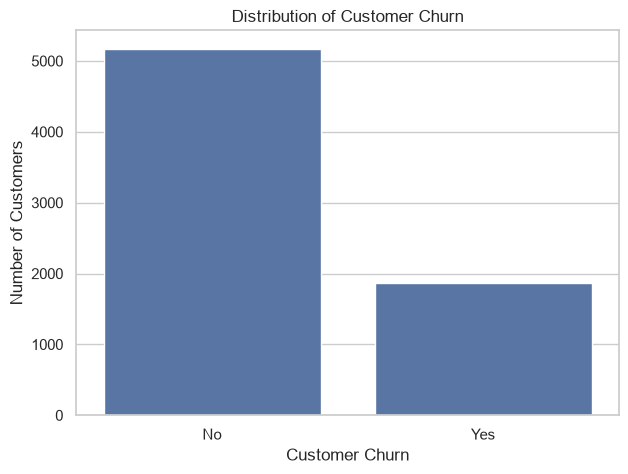


Customer churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [7]:
# Count customers in each churn category
churn_counts = df["Churn"].value_counts()

# Display the number of customers in each category
print("Customer churn counts:")
print(churn_counts)

# Create a bar chart
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")

plt.title("Distribution of Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

# Display the percentage of each category
print("\nCustomer churn percentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Customer tenure summary:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


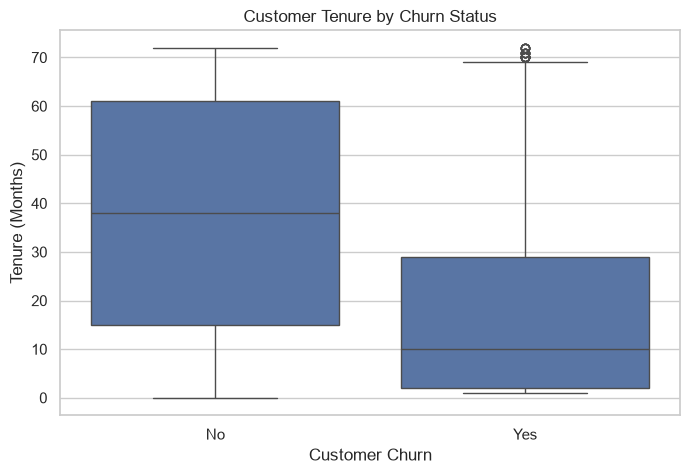

In [8]:
# Display summary statistics for customer tenure
print("Customer tenure summary:")
print(df["tenure"].describe())

# Create a box plot to compare tenure between churn groups
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.show()

Average Monthly Charges by Churn Status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


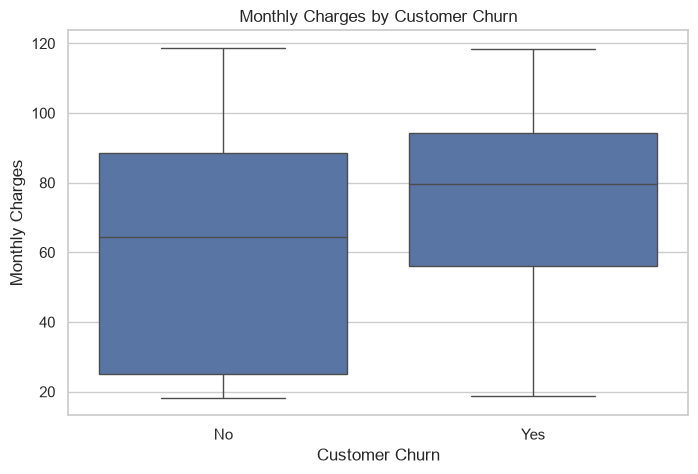

In [9]:
# Calculate average monthly charges for each churn category
monthly_charges = df.groupby("Churn")["MonthlyCharges"].mean()

# Display the average monthly charges
print("Average Monthly Charges by Churn Status:")
print(monthly_charges.round(2))

# Create a box plot to compare monthly charges
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.show()

Churn Percentage by Contract Type:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


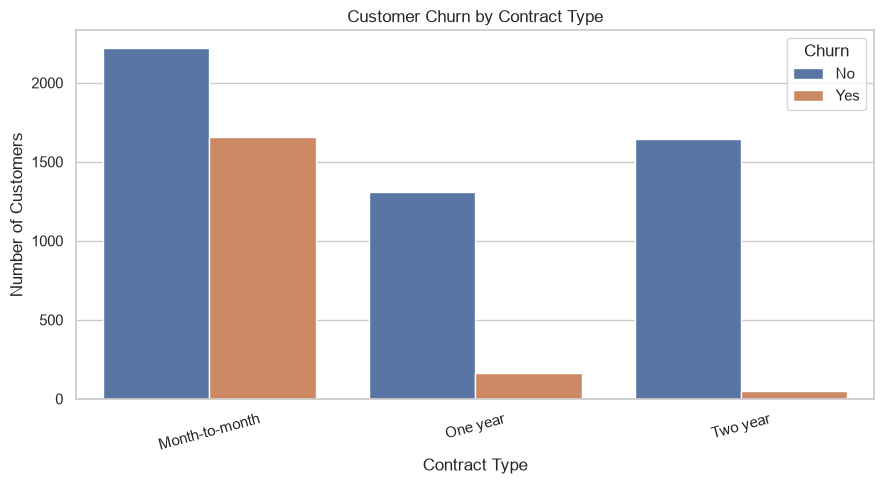

In [10]:
# Calculate the percentage of customers who churned for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

# Display the churn percentages
print("Churn Percentage by Contract Type:")
print(contract_churn.round(2))

# Create a count plot
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

## 5. Summary of Exploratory Data Analysis

The exploratory data analysis examined the distribution of customer churn and the relationships between churn, customer tenure, monthly charges, and contract type.

The analysis provides several important observations:

- **Churn distribution:** The dataset contains more customers who stayed with the company than customers who left. This class imbalance should be considered when evaluating the classification models.
- **Customer tenure:** Customers who churned generally had shorter tenures than customers who remained with the company.
- **Monthly charges:** Comparing monthly charges across churn categories helps identify whether differences in customer charges are associated with churn.
- **Contract type:** Customers with month-to-month contracts generally show higher churn rates than customers with longer-term contracts.

These observations help us understand the dataset and identify potentially useful features for prediction. However, the relationships observed during EDA do not establish causation.

The next stage will focus on preparing the dataset for machine learning by checking data types, handling missing values, identifying the target variable, and preparing the features for model training.

## 6. Data Cleaning and Preparation

Before training machine learning models, the dataset must be checked and prepared to ensure that the data is suitable for analysis.

The following steps will be carried out:

1. Check for duplicate records and examine the dataset for data quality issues.
2. Convert columns to appropriate data types.
3. Identify and handle missing values.
4. Separate the input features from the target variable.
5. Identify numerical and categorical features.
6. Prepare the data using suitable preprocessing techniques.

Numerical features may require scaling because they can have different ranges. Categorical features must be converted into a numerical representation because machine learning algorithms generally require numerical input.

These preparation steps will help ensure that the models receive consistent and appropriately formatted data during training and evaluation.

In [11]:
# Count duplicate rows in the dataset
duplicate_count = df.duplicated().sum()

# Display the result
print("Number of duplicate rows:", duplicate_count)

# Display the dataset size before removing duplicates
print("Dataset shape before duplicate removal:", df.shape)

Number of duplicate rows: 0
Dataset shape before duplicate removal: (7043, 21)


In [12]:

# Convert TotalCharges to numeric values
# Invalid or blank values will be converted to NaN
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Count missing values after conversion
print("Missing values after converting TotalCharges:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Display the data type
print("\nTotalCharges data type:", df["TotalCharges"].dtype)


Missing values after converting TotalCharges:
TotalCharges    11
dtype: int64

TotalCharges data type: float64


In [13]:

# Count missing values in each column
missing_summary = df.isnull().sum()

# Display only columns with missing values
print("Columns containing missing values:")
print(missing_summary[missing_summary > 0])

# Calculate the total number of missing values
print("\nTotal missing values:", missing_summary.sum())

# Calculate the percentage of missing values in each affected column
print("\nPercentage of missing values:")
print(
    (missing_summary[missing_summary > 0] / len(df) * 100).round(2)
)


Columns containing missing values:
TotalCharges    11
dtype: int64

Total missing values: 11

Percentage of missing values:
TotalCharges    0.16
dtype: float64



## 7. Feature Selection and Target Variable

In this project, the target variable is `Churn`, which indicates whether a customer has left the telecommunications company.

The remaining relevant columns will be used as input features to predict customer churn.

The `customerID` column will be excluded because it is an identifier rather than a meaningful predictive feature. Including it could introduce irrelevant information into the models.

The target variable will be converted into numerical values:
- `No` will be represented as `0`.
- `Yes` will be represented as `1`.

Separating the input features from the target variable is necessary before splitting the data into training and testing sets. This helps us train the models using customer information while evaluating their ability to predict churn.


In [14]:

# Create the input features by removing the target and customer ID
X = df.drop(columns=["Churn", "customerID"])

# Convert the target variable into numerical values
y = df["Churn"].map({"No": 0, "Yes": 1})

# Display the dimensions of the features and target
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Display the target class counts
print("\nTarget class distribution:")
print(y.value_counts())

# Check for any missing target values
print("\nMissing target values:", y.isnull().sum())


Features shape: (7043, 19)
Target shape: (7043,)

Target class distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64

Missing target values: 0


In [15]:

# Identify numerical features
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Display the feature groups
print("Numerical features:")
print(numerical_features)

print("\nNumber of numerical features:", len(numerical_features))

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of numerical features: 4

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15


C:\Users\janit\AppData\Local\Temp\ipykernel_22772\4152055556.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(



## 8. Data Preprocessing Strategy

Machine learning algorithms require data to be prepared in a suitable format. Therefore, this project will use a preprocessing pipeline to handle missing values and transform the input features.

The following techniques will be applied:

**1. Numerical features**

- Missing values will be replaced using the median value of each numerical feature.
- Standardisation will be applied using `StandardScaler` so that numerical features have a mean close to zero and a standard deviation close to one.

**2. Categorical features**

- Missing values will be replaced using the most frequent category.
- One-hot encoding will convert categorical values into numerical columns that can be used by the machine learning algorithms.

**3. Preprocessing pipeline**

A `ColumnTransformer` will apply the appropriate transformations to each feature group. These transformations will be combined with the machine learning models in pipelines.

The preprocessing steps will be fitted using the training data only. This helps prevent data leakage, where information from the test dataset could influence model training.

Using pipelines also ensures that the same preprocessing steps are applied consistently during training, cross-validation, and testing.


In [16]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the training and testing sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check the churn distribution in each set
print("\nChurn percentage in training set:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nChurn percentage in testing set:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Training features: (5634, 19)
Testing features: (1409, 19)

Training target: (5634,)
Testing target: (1409,)

Churn percentage in training set:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

Churn percentage in testing set:
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [17]:

# Create the numerical preprocessing pipeline
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create the categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_transformer, numerical_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!
